# 03 - Explaining the Churn Model with SHAP
**Goal:** go beyond "which features matter overall" to answer *why does the model think THIS customer will churn?*

**Inputs (run notebooks 01 and 02 first):** `data/processed/telco_clean.csv` and the fitted model `outputs/best_churn_model.joblib`.

**How SHAP works, in plain words:** for each customer, SHAP splits the model's predicted churn probability into contributions from each feature, relative to the average prediction. A feature with a value of **+0.10** pushed this customer's churn probability **up by 10 percentage points**; **-0.05** pushed it down by 5. Contributions add up exactly to the final prediction (checked below).

Here SHAP is computed on the **held-out test customers** only, on the original input columns (so `Contract` is one feature, not three one-hot columns).

## 1. Setup

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
np.random.seed(42)

PROCESSED_PATH = "../data/processed/telco_clean.csv"
MODEL_PATH = "../outputs/best_churn_model.joblib"
OUT_DIR = Path("../outputs")
RANDOM_STATE = 42

## 2. Load data and model, recreate the exact test set from notebook 02

In [2]:
clean = pd.read_csv(PROCESSED_PATH)
y = clean["Churn_Value"].astype(int)
ids = clean["CustomerID"]
X = clean.drop(columns=["CustomerID", "Churn_Value", "Churn_Reason"])

# Same split settings as notebook 02 -> identical train/test customers
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

model = joblib.load(MODEL_PATH)
proba_test = model.predict_proba(X_test)[:, 1]
print(f"Test ROC-AUC: {roc_auc_score(y_test, proba_test):.3f}  (should match notebook 02: 0.858)")
print("Test customers:", len(X_test))

Test ROC-AUC: 0.857  (should match notebook 02: 0.858)
Test customers: 1409


## 3. Compute SHAP values
The SHAP explainer needs numbers, so the three text columns are temporarily encoded as integers and decoded again inside the prediction function. The model itself is unchanged.

In [3]:
cat_cols = ["Contract", "Internet_Service", "Payment_Method"]
levels = {c: sorted(X[c].unique()) for c in cat_cols}

def encode(df):
    e = df.copy()
    for c in cat_cols:
        e[c] = e[c].map({v: i for i, v in enumerate(levels[c])})
    return e.astype(float)

def decode(arr):
    d = pd.DataFrame(arr, columns=X.columns)
    for c in cat_cols:
        d[c] = d[c].round().astype(int).map(dict(enumerate(levels[c])))
    for c in X.columns:
        if c not in cat_cols:
            d[c] = d[c].astype(X[c].dtype)
    return d

def predict_churn(arr):
    return model.predict_proba(decode(arr))[:, 1]

background = encode(shap.sample(X_train, 100, random_state=RANDOM_STATE))
X_test_enc = encode(X_test)

n_feat = X.shape[1]
explainer = shap.Explainer(predict_churn, shap.maskers.Independent(background.to_numpy(), max_samples=100),
                           algorithm="permutation", feature_names=list(X.columns))
sv = explainer(X_test_enc.to_numpy(), max_evals=3 * (2 * n_feat + 1), silent=True)

# Additivity check: base value + sum of contributions = model prediction
err = np.abs(sv.base_values + sv.values.sum(axis=1) - proba_test).max()
print(f"SHAP values: {sv.values.shape} | max additivity error: {err:.2e}")
print(f"Average predicted churn probability (base value): {sv.base_values.mean():.3f}")

SHAP values: (1409, 21) | max additivity error: 2.22e-15
Average predicted churn probability (base value): 0.295


## 4. Global view: which features move churn risk the most?

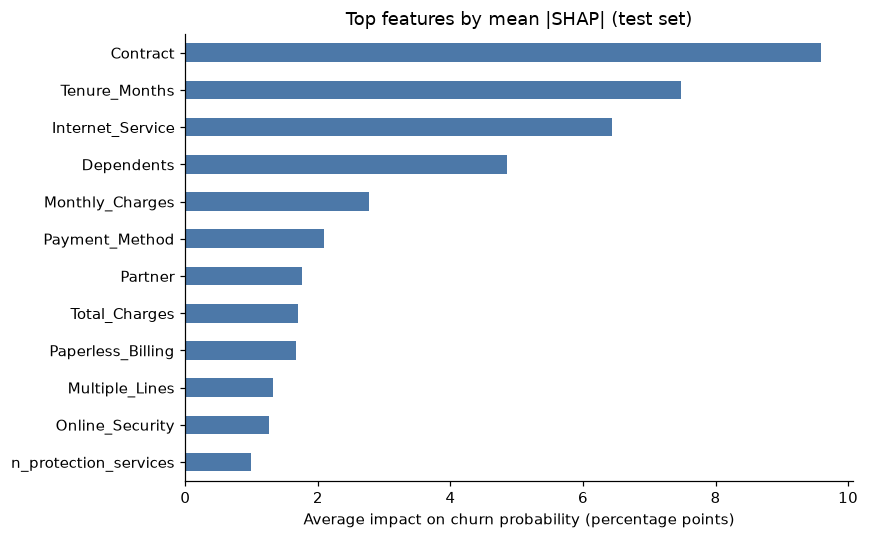

Contract            9.6
Tenure_Months       7.5
Internet_Service    6.4
Dependents          4.9
Monthly_Charges     2.8
Payment_Method      2.1
Partner             1.8
Total_Charges       1.7


In [4]:
mean_abs = pd.Series(np.abs(sv.values).mean(axis=0), index=X.columns).sort_values()
ax = (mean_abs.tail(12) * 100).plot.barh(figsize=(8, 5), color="#4c78a8")
ax.set_xlabel("Average impact on churn probability (percentage points)")
ax.set_title("Top features by mean |SHAP| (test set)")
plt.tight_layout()
plt.savefig(OUT_DIR / "shap_importance.png", dpi=150)
plt.show()
print((mean_abs.sort_values(ascending=False).head(8) * 100).round(1).to_string())

**Findings (global)**
- On average, **contract type moves a customer's churn probability by about 9.5 percentage points**, followed by **tenure (7.5 pp)**, **internet service (6.4 pp)** and **dependents (4.8 pp)**. Monthly charges (2.8 pp) and payment method (2.1 pp) matter less.
- This ranking is close to, but not identical to, the permutation importance in notebook 02 (e.g. internet service and dependents swap places). The two methods measure different things, but they agree on the top group.

### Direction of effect (numeric and yes/no features)
Each dot is one customer. Position left/right shows whether the feature pushed that customer's risk down/up; colour shows the feature value (red = high, blue = low). Text columns are shown separately below, because colouring by an integer code would be meaningless.

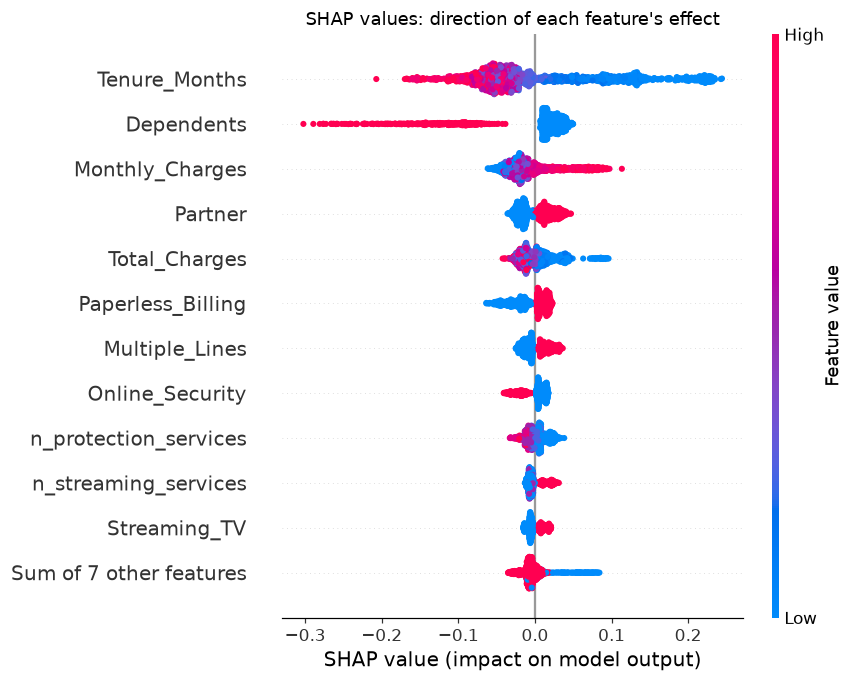

In [5]:
non_cat = [c for c in X.columns if c not in cat_cols]
idx = [list(X.columns).index(c) for c in non_cat]
expl_num = shap.Explanation(values=sv.values[:, idx], base_values=sv.base_values,
                            data=X_test[non_cat].to_numpy(), feature_names=non_cat)
plt.figure()
shap.plots.beeswarm(expl_num, max_display=12, show=False)
plt.title("SHAP values: direction of each feature's effect")
plt.tight_layout()
plt.savefig(OUT_DIR / "shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

### Text columns: average effect of each category

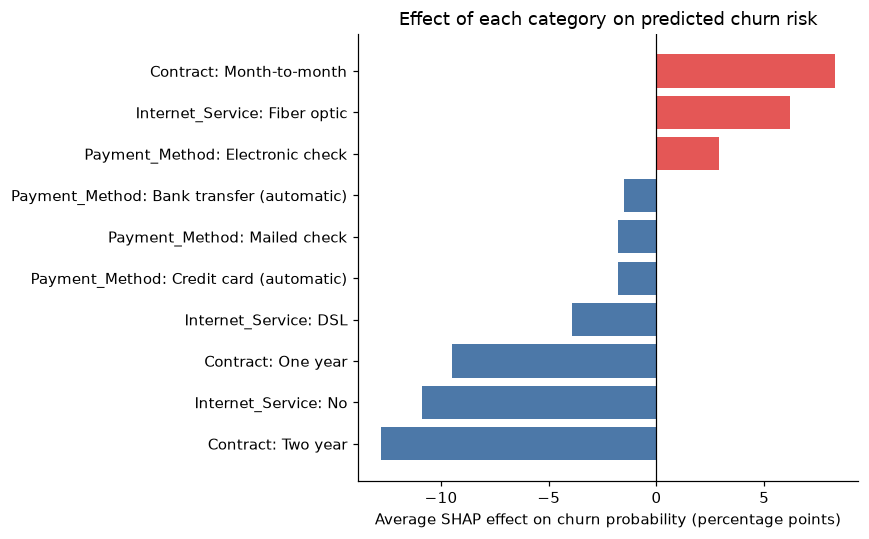

,feature,level,customers,avg_effect_pp
0,Contract,Two year,336,-12.8
1,Internet_Service,No,312,-10.9
2,Contract,One year,300,-9.5
3,Internet_Service,DSL,484,-3.9
4,Payment_Method,Credit card (automatic),309,-1.8
5,Payment_Method,Mailed check,326,-1.8
6,Payment_Method,Bank transfer (automatic),300,-1.5
7,Payment_Method,Electronic check,474,2.9
8,Internet_Service,Fiber optic,613,6.2
9,Contract,Month-to-month,773,8.3


In [6]:
rows = []
for c in cat_cols:
    j = list(X.columns).index(c)
    tmp = pd.DataFrame({"level": X_test[c].values, "shap": sv.values[:, j] * 100})
    g = tmp.groupby("level")["shap"].agg(["mean", "size"]).reset_index()
    g.insert(0, "feature", c)
    rows.append(g)
cat_effects = pd.concat(rows).rename(columns={"mean": "avg_effect_pp", "size": "customers"})
cat_effects["avg_effect_pp"] = cat_effects["avg_effect_pp"].round(1)
cat_effects["label"] = cat_effects["feature"] + ": " + cat_effects["level"]
cat_effects = cat_effects.sort_values("avg_effect_pp")

colors = np.where(cat_effects["avg_effect_pp"] > 0, "#e45756", "#4c78a8")
plt.figure(figsize=(8, 5))
plt.barh(cat_effects["label"], cat_effects["avg_effect_pp"], color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Average SHAP effect on churn probability (percentage points)")
plt.title("Effect of each category on predicted churn risk")
plt.tight_layout()
plt.savefig(OUT_DIR / "shap_categorical_levels.png", dpi=150)
plt.show()
cat_effects[["feature", "level", "customers", "avg_effect_pp"]].reset_index(drop=True)

**Findings (categories)** - average effect on churn probability, relative to the average customer:
- **Month-to-month contract: +8.2 pp**, versus **one-year -9.3 pp** and **two-year -12.8 pp**.
- **Fibre optic: +6.2 pp**; DSL -3.9 pp; no internet service -11.0 pp.
- **Electronic check: +2.9 pp**; the other three payment methods are slightly protective (about -1.5 to -1.8 pp).

These are associations the model learned from one snapshot of data, not proof that changing a contract or payment method would *cause* a change in churn.

## 5. How does risk change with tenure and monthly charges?

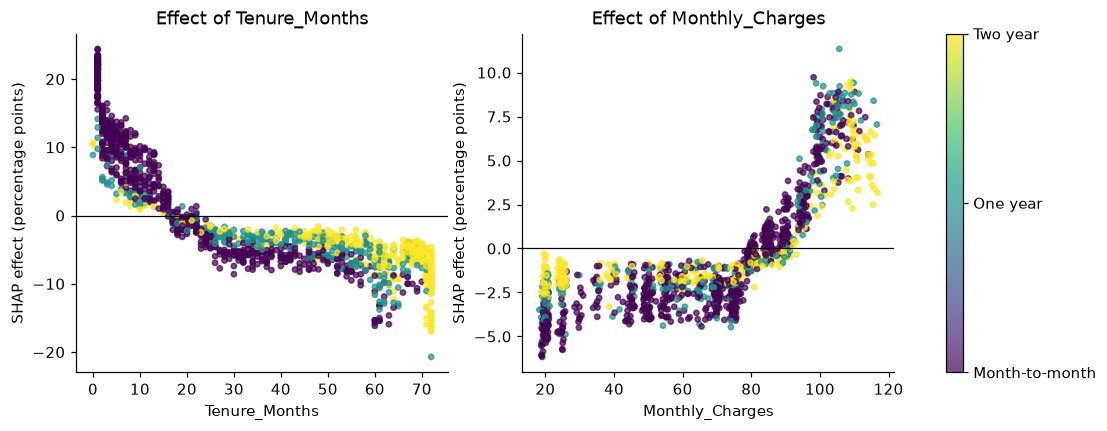

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["Tenure_Months", "Monthly_Charges"]):
    j = list(X.columns).index(col)
    sc = ax.scatter(X_test[col], sv.values[:, j] * 100, c=X_test["Contract"].map({"Month-to-month": 0, "One year": 1, "Two year": 2}),
                    cmap="viridis", s=12, alpha=0.7)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xlabel(col)
    ax.set_ylabel("SHAP effect (percentage points)")
    ax.set_title(f"Effect of {col}")
cbar = fig.colorbar(sc, ax=axes, ticks=[0, 1, 2])
cbar.ax.set_yticklabels(["Month-to-month", "One year", "Two year"])
plt.savefig(OUT_DIR / "shap_dependence.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Why does the model flag *this* customer?
Waterfall charts for one very high-risk and one very low-risk customer from the test set. Each bar shows how one feature moved the prediction from the average (left) to this customer's final probability (right).

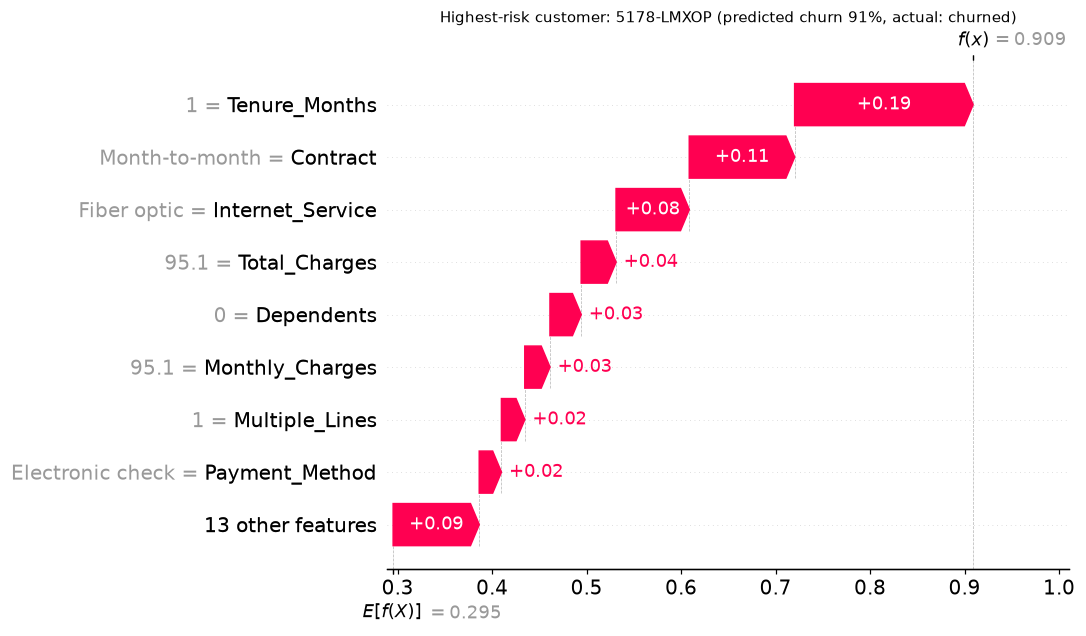

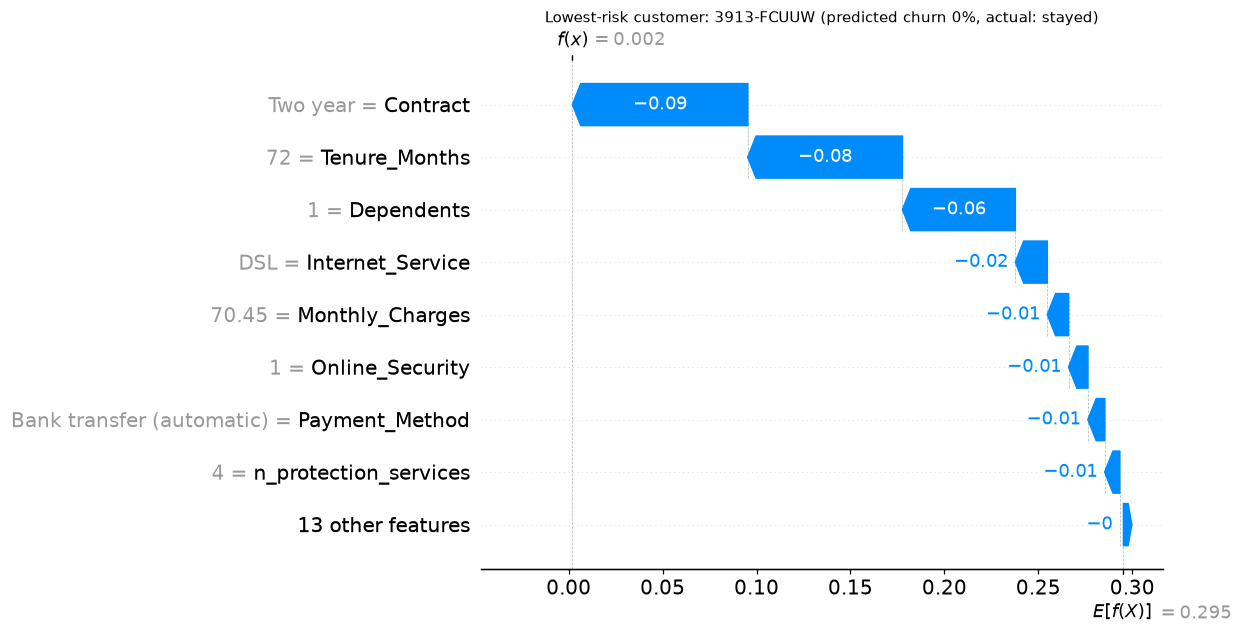

In [8]:
def explain_customer(position, title, filename):
    row = X_test.iloc[position]
    expl = shap.Explanation(values=sv.values[position], base_values=sv.base_values[position],
                            data=row.to_numpy(dtype=object), feature_names=list(X.columns))
    plt.figure()
    shap.plots.waterfall(expl, max_display=9, show=False)
    plt.title(f"{title}: {ids.loc[row.name]} (predicted churn {proba_test[position]:.0%}, actual: "
              f"{'churned' if y_test.iloc[position] else 'stayed'})", fontsize=10)
    plt.savefig(OUT_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()

hi = int(np.argmax(proba_test))
lo = int(np.argmin(proba_test))
explain_customer(hi, "Highest-risk customer", "shap_waterfall_high_risk.png")
explain_customer(lo, "Lowest-risk customer", "shap_waterfall_low_risk.png")

## 7. Reason codes for every test customer
A retention team needs a short reason next to each risky customer. For each customer this lists the **top 3 features pushing their risk up**, with the size of each push in percentage points (pp). Saved to `outputs/shap_top_drivers_test.csv`.

In [9]:
feature_names = np.array(X.columns)

def reason_text(i, j):
    return f"{feature_names[j]} = {X_test.iloc[i, j]} ({sv.values[i, j] * 100:+.1f} pp)"

records = []
for i in range(len(X_test)):
    order = np.argsort(-sv.values[i])[:3]          # biggest upward pushes
    records.append({
        "CustomerID": ids.loc[X_test.index[i]],
        "churn_probability": round(float(proba_test[i]), 4),
        "actual_churned": int(y_test.iloc[i]),
        "driver_1": reason_text(i, order[0]),
        "driver_2": reason_text(i, order[1]),
        "driver_3": reason_text(i, order[2]),
    })
drivers = pd.DataFrame(records).sort_values("churn_probability", ascending=False)
drivers.to_csv(OUT_DIR / "shap_top_drivers_test.csv", index=False)
drivers.head(8)

,CustomerID,churn_probability,actual_churned,driver_1,driver_2,driver_3
1090,5178-LMXOP,0.9090,1,Tenure_Months = 1 (+18.9 pp),Contract = Month-to-month (+11.2 pp),Internet_Service = Fiber optic (+7.7 pp)
1221,0295-PPHDO,0.9023,1,Tenure_Months = 1 (+19.3 pp),Contract = Month-to-month (+11.8 pp),Internet_Service = Fiber optic (+8.7 pp)
51,7181-BQYBV,0.8971,1,Tenure_Months = 1 (+18.5 pp),Contract = Month-to-month (+11.1 pp),Monthly_Charges = 102.45 (+8.2 pp)
1109,1069-XAIEM,0.8875,1,Tenure_Months = 1 (+20.9 pp),Contract = Month-to-month (+13.0 pp),Internet_Service = Fiber optic (+9.0 pp)
1175,6861-XWTWQ,0.8853,1,Tenure_Months = 7 (+12.4 pp),Contract = Month-to-month (+11.1 pp),Internet_Service = Fiber optic (+8.8 pp)
1164,8884-ADFVN,0.8853,1,Tenure_Months = 7 (+11.4 pp),Contract = Month-to-month (+10.0 pp),Internet_Service = Fiber optic (+8.7 pp)
630,4587-VVTOX,0.8816,1,Tenure_Months = 6 (+11.4 pp),Contract = Month-to-month (+10.1 pp),Internet_Service = Fiber optic (+8.5 pp)
1138,1400-MMYXY,0.8780,1,Tenure_Months = 3 (+13.1 pp),Contract = Month-to-month (+10.6 pp),Internet_Service = Fiber optic (+8.2 pp)


## 8. Summary
- SHAP confirms the main story from notebooks 01 and 02: **short tenure, month-to-month contracts and fibre-optic service push churn risk up; long contracts, no internet service and dependents push it down.**
- It adds a per-customer answer: the waterfall charts and `shap_top_drivers_test.csv` show the **specific reasons** behind each prediction, which a retention team can act on.
- Limitations: explanations cover the 1,409 held-out test customers only; SHAP describes what the *model* does, not necessarily what causes churn in the real world; and `Gender` and location were deliberately excluded from the model, so they cannot appear here.